# Vision — Analisis Kesalahan (gambar mana yang salah, dan kenapa?)
**Kapan dipakai:** SETELAH model klasifikasi jadi, untuk mencari bahan perbaikan (augmentasi,
membersihkan label, data tambahan) dan untuk slide presentasi/laporan.

**Bentuk data yang didukung** (pilih satu sel di bagian Baca data):
1. CSV `id,label` + gambar dalam satu folder (aktif)
2. folder per kelas: `train/<kelas>/*.jpg`
3. label tertulis di nama file: `Abyssinian_12.jpg` → `Abyssinian`

**Langkah:** embedding ResNet50 + LogisticRegression → prediksi out-of-fold (tiap gambar train
ditebak model yang TIDAK melihatnya, jadi tebakannya jujur) → lihat:
- pasangan kelas yang paling sering tertukar;
- gambar "yakin tapi salah" (curiga label salah) dan gambar paling ragu;
- irisan (gelap/terang, kontras, ukuran asli kecil, grayscale, kolom metadata) yang paling
  sering salah.

**Data demo:** `pets` = foto 10 ras kucing/anjing (Oxford-IIIT Pet), jumlah per kelas 200 → 30,
ada GIF/PNG berekstensi `.jpg`, grayscale, RGBA. Kolom tambahan `spesies` dipakai sebagai irisan.

In [1]:
import glob
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageOps
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from torch import nn
from torchvision import models

## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/vision/pets"    # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/train.csv"
TRAIN_IMAGE_FOLDER = f"{DATA_FOLDER}/train"
PRETRAINED = "../../pretrained"
OUTPUT_FOLDER = "../../outputs/vision/analisis_kesalahan"   # di luar repo
os.makedirs(OUTPUT_FOLDER, exist_ok=True)

ID_COL = "id"           # kolom nama file gambar
TARGET = "label"        # kolom kelas
IMAGE_EXTENSION = ""    # isi ".jpg" bila kolom id TIDAK memuat ekstensi (misalnya "img_01")
META_COLS = ["spesies"]   # kolom lain di CSV untuk irisan, [] bila tidak ada
IMAGE_SIZE = 224
BATCH_SIZE = 64
N_FOLDS = 5
N_EXAMPLES = 10         # gambar per grid
SEED = 42
DEVICE = "cpu"
if torch.cuda.is_available():
    DEVICE = "cuda"
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)   # normalisasi warna ImageNet
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

## Baca data — bentuk 1: CSV `id,label` + folder gambar (aktif)

In [3]:
train = pd.read_csv(TRAIN_CSV)
train["path"] = TRAIN_IMAGE_FOLDER + "/" + train[ID_COL].astype(str) + IMAGE_EXTENSION
print("train:", train.shape)
print("contoh path:", train["path"].iloc[0])
print(train[TARGET].value_counts())

train: (805, 4)
contoh path: ../../data_latihan/vision/pets/train/Siamese_24.jpg
label
Abyssinian                    149
beagle                        135
pug                           120
Persian                       105
Siamese                        82
shiba_inu                      67
Bengal                         53
yorkshire_terrier              41
Egyptian_Mau                   30
staffordshire_bull_terrier     23
Name: count, dtype: int64


## (Alternatif) bentuk 2: folder per kelas `train/<kelas>/*.jpg`

In [4]:
# rows = []
# for class_name in sorted(os.listdir(TRAIN_IMAGE_FOLDER)):
#     for path in sorted(glob.glob(f"{TRAIN_IMAGE_FOLDER}/{class_name}/*")):
#         rows.append([os.path.basename(path), class_name, path])
# train = pd.DataFrame(rows, columns=[ID_COL, TARGET, "path"])
# META_COLS = []

## (Alternatif) bentuk 3: label di nama file `Abyssinian_12.jpg`

In [5]:
# train = pd.DataFrame()
# train["path"] = sorted(glob.glob(f"{TRAIN_IMAGE_FOLDER}/*"))
# train[ID_COL] = train["path"].apply(os.path.basename)
# train[TARGET] = train[ID_COL].str.rsplit("_", n=1).str[0]
# META_COLS = []

## Ciri sederhana tiap gambar (untuk irisan) + gambar → tensor
Kecerahan = rata-rata abu-abu (0 gelap – 255 terang). Kontras = simpangan bakunya.
Ukuran dan mode diambil dari file ASLI, sebelum diseragamkan.

In [6]:
def load_images(paths):
    images = np.zeros((len(paths), IMAGE_SIZE, IMAGE_SIZE, 3), dtype=np.uint8)
    rows = []
    for i, path in enumerate(paths):
        original = Image.open(path)
        image = original.convert("RGB")
        gray = np.asarray(image.convert("L"), dtype=float)
        rows.append([original.mode, original.width, original.height, gray.mean(), gray.std()])
        images[i] = ImageOps.fit(image, (IMAGE_SIZE, IMAGE_SIZE))
    traits = pd.DataFrame(rows, columns=["mode", "lebar", "tinggi", "kecerahan", "kontras"])
    return torch.tensor(images).permute(0, 3, 1, 2), traits


images_all, traits = load_images(train["path"])
for column in traits.columns:
    train[column] = traits[column].to_numpy()
train["rasio"] = train["lebar"] / train["tinggi"]
train[["mode", "lebar", "tinggi", "kecerahan", "kontras", "rasio"]].describe(include="all")

,mode,lebar,tinggi,kecerahan,kontras,rasio
count,805,805.000000,805.000000,805.000000,805.000000,805.000000
unique,3,NaN,NaN,NaN,NaN,NaN
top,RGB,NaN,NaN,NaN,NaN,NaN
freq,800,NaN,NaN,NaN,NaN,NaN
mean,NaN,433.079503,387.936646,115.247924,56.303862,1.170444
std,NaN,152.486109,143.125201,33.128200,13.404370,0.334639
min,NaN,133.000000,150.000000,16.456561,16.731626,0.516000
25%,NaN,333.000000,333.000000,94.057458,47.112929,0.758000
50%,NaN,500.000000,375.000000,115.056757,56.305097,1.333333
75%,NaN,500.000000,500.000000,135.194271,65.332070,1.483680


## Embedding ResNet50 beku
Model lain? Ambil blok backbone dari `klasifikasi_embedding`. Yang dianalisis sebaiknya model
yang sama dengan model untuk prediksi akhir.

In [7]:
backbone = models.resnet50(weights=None)
backbone.load_state_dict(torch.load(f"{PRETRAINED}/resnet50/model.pth", map_location="cpu"))
backbone.fc = nn.Identity()
backbone = backbone.to(DEVICE)
backbone.eval()

batches = []
with torch.no_grad():
    for start in range(0, len(images_all), BATCH_SIZE):
        batch = (images_all[start:start + BATCH_SIZE].float() / 255 - MEAN) / STD
        batches.append(backbone(batch.to(DEVICE)).cpu())
X_all = torch.cat(batches).numpy()
print("embedding:", X_all.shape)

embedding: (805, 2048)


## Prediksi out-of-fold (tiap gambar ditebak model yang tidak melihatnya)
`cross_val_predict` melatih `N_FOLDS` model; tiap gambar ditebak model dari fold lain.

In [8]:
model = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=3000,
                                                           class_weight="balanced"))
folds = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
probabilities = cross_val_predict(model, X_all, train[TARGET], cv=folds, method="predict_proba")
classes = np.array(sorted(train[TARGET].unique()))
train["tebakan"] = classes[probabilities.argmax(axis=1)]
train["yakin"] = probabilities.max(axis=1)
train["salah"] = train["tebakan"] != train[TARGET]
print("salah:", train["salah"].sum(), "dari", len(train))
print(classification_report(train[TARGET], train["tebakan"]))

salah: 25 dari 805
                            precision    recall  f1-score   support

                Abyssinian       0.92      0.98      0.95       149
                    Bengal       0.83      0.85      0.84        53
              Egyptian_Mau       0.92      0.77      0.84        30
                   Persian       0.99      0.96      0.98       105
                   Siamese       1.00      0.99      0.99        82
                    beagle       1.00      1.00      1.00       135
                       pug       1.00      1.00      1.00       120
                 shiba_inu       0.98      0.97      0.98        67
staffordshire_bull_terrier       1.00      1.00      1.00        23
         yorkshire_terrier       1.00      1.00      1.00        41

                  accuracy                           0.97       805
                 macro avg       0.97      0.95      0.96       805
              weighted avg       0.97      0.97      0.97       805



## Kelas mana yang tertukar?
`normalize="true"`: tiap baris dijumlah 1, jadi kelas kecil dan besar bisa dibandingkan.

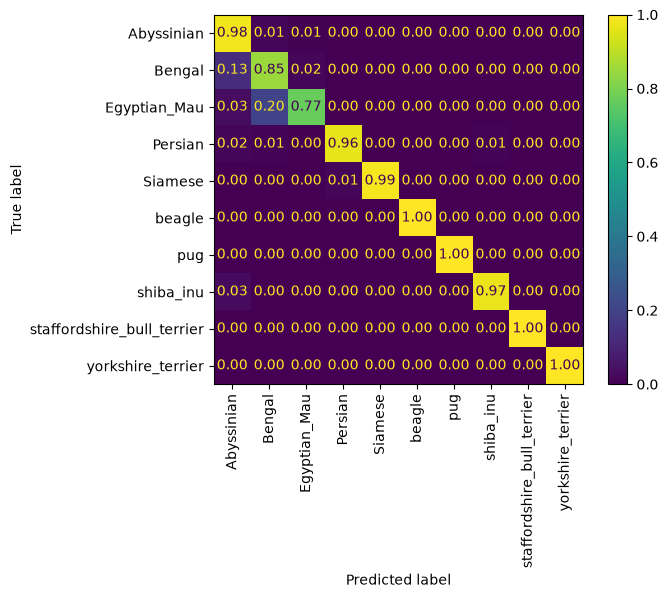

pasangan paling sering tertukar (label asli, tebakan):
label         tebakan     
Bengal        Abyssinian      7
Egyptian_Mau  Bengal          6
Abyssinian    Bengal          2
shiba_inu     Abyssinian      2
Persian       Abyssinian      2
Abyssinian    Egyptian_Mau    1
Egyptian_Mau  Abyssinian      1
Bengal        Egyptian_Mau    1
Persian       Bengal          1
              shiba_inu       1
dtype: int64


In [9]:
ConfusionMatrixDisplay.from_predictions(train[TARGET], train["tebakan"], xticks_rotation=90,
                                        normalize="true", values_format=".2f")
plt.savefig(f"{OUTPUT_FOLDER}/confusion.png", dpi=120, bbox_inches="tight")
plt.show()

wrong = train[train["salah"]]
pair_counts = wrong.groupby([TARGET, "tebakan"]).size()
pair_counts = pair_counts.sort_values(ascending=False)
print("pasangan paling sering tertukar (label asli, tebakan):")
print(pair_counts.head(10))

## Yakin tapi salah (curiga label salah) dan paling ragu
"Yakin tapi salah" sering berarti label soal yang keliru, atau dua kelas yang memang sangat
mirip. Daftar nama filenya disimpan di `OUTPUT_FOLDER` untuk dicek manual.

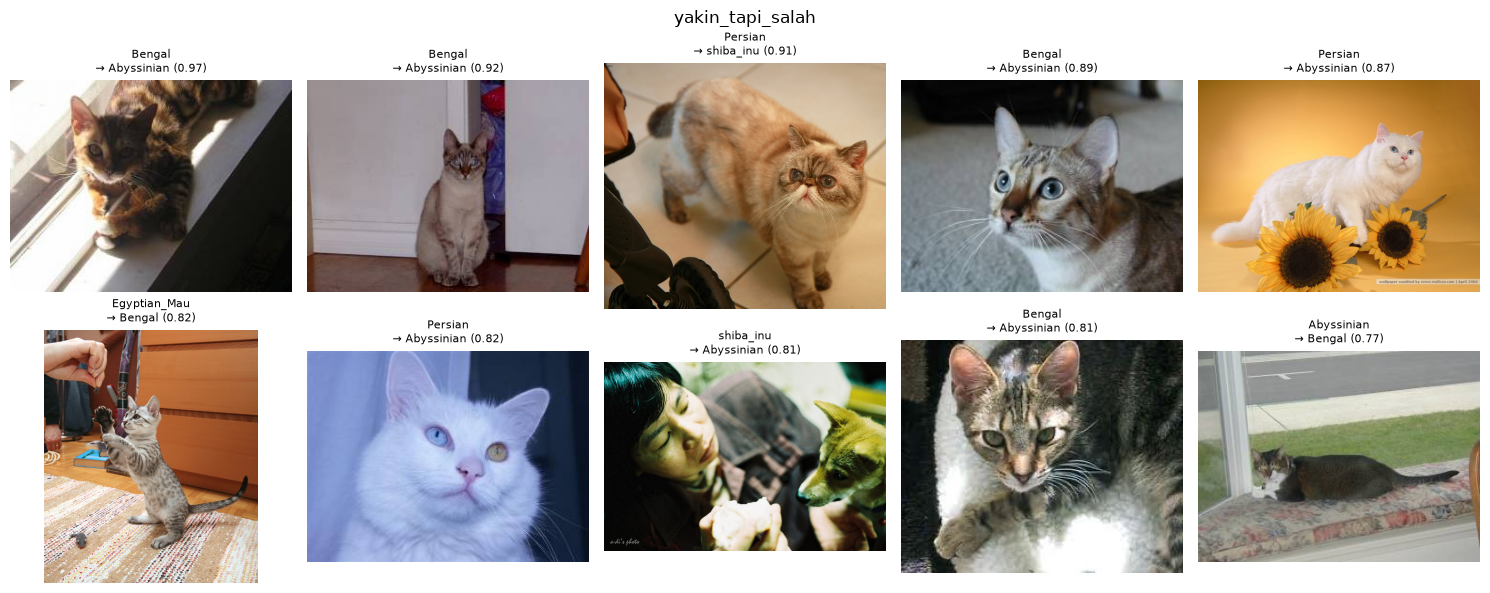

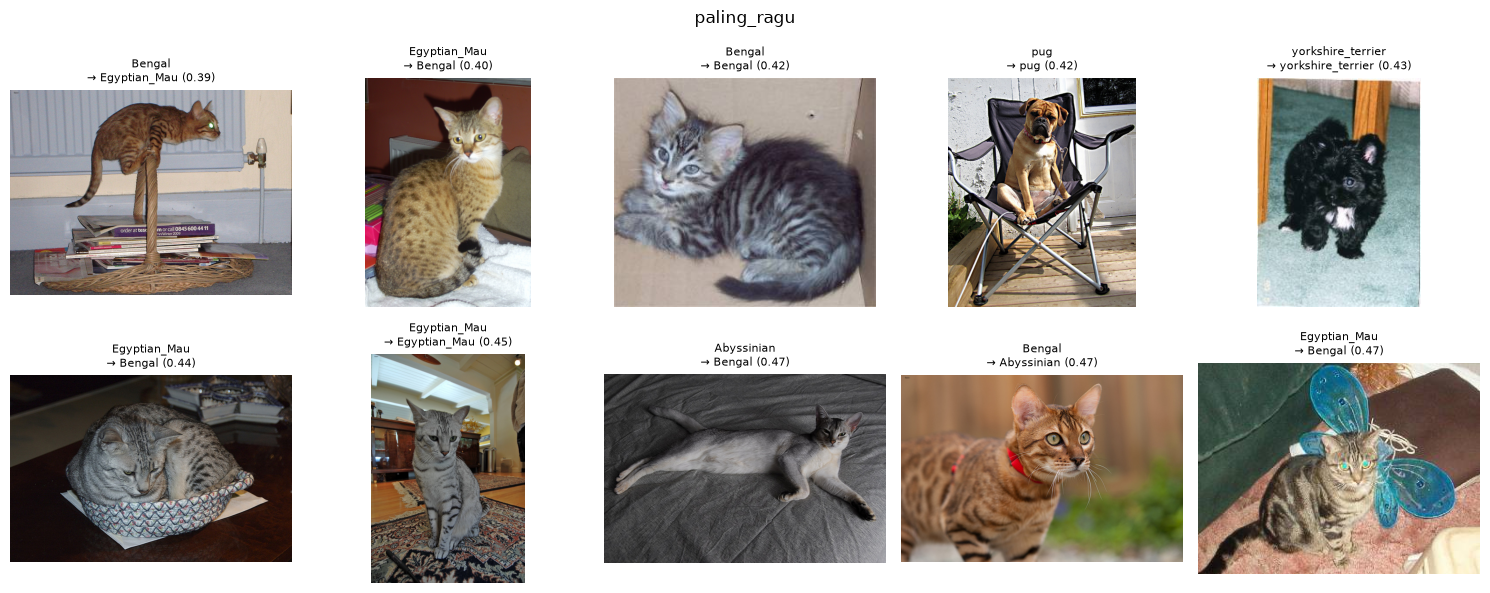

In [10]:
confident_wrong = wrong.sort_values("yakin", ascending=False).head(N_EXAMPLES)
unsure = train.sort_values("yakin").head(N_EXAMPLES)
for title, table in [("yakin_tapi_salah", confident_wrong), ("paling_ragu", unsure)]:
    fig, axes = plt.subplots(2, N_EXAMPLES // 2, figsize=(15, 6))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, row in zip(axes.ravel(), table.itertuples()):
        ax.imshow(Image.open(row.path).convert("RGB"))
        ax.set_title(f"{getattr(row, TARGET)}\n→ {row.tebakan} ({row.yakin:.2f})", fontsize=8)
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_FOLDER}/{title}.png", dpi=100)
    plt.show()
confident_wrong[[ID_COL, TARGET, "tebakan", "yakin"]].to_csv(
    f"{OUTPUT_FOLDER}/curiga_label_salah.csv", index=False)

## Irisan: kelompok gambar mana yang paling sering salah?
`pd.qcut` membagi gambar jadi 4 kelompok sama banyak (kecil → besar). Bandingkan dengan
rata-rata kesalahan; kelompok yang jauh di atasnya = titik lemah model.

In [11]:
print("rata-rata kesalahan:", round(train["salah"].mean(), 3))
for column in ["kecerahan", "kontras", "lebar", "rasio"]:
    groups = pd.qcut(train[column], 4, duplicates="drop")
    error_rate = train.groupby(groups, observed=True)["salah"].mean()
    print(error_rate.round(3), "\n")
for column in ["mode"] + META_COLS:
    summary = train.groupby(column)["salah"].agg(["mean", "size"])
    print(summary.round(3), "\n")

rata-rata kesalahan: 0.031
kecerahan
(16.456, 94.057]      0.040
(94.057, 115.057]     0.030
(115.057, 135.194]    0.025
(135.194, 229.918]    0.030
Name: salah, dtype: float64 

kontras
(16.730999999999998, 47.113]    0.025
(47.113, 56.305]                0.050
(56.305, 65.332]                0.020
(65.332, 105.741]               0.030
Name: salah, dtype: float64 

lebar
(132.999, 333.0]    0.041
(333.0, 500.0]      0.024
(500.0, 1886.0]     0.097
Name: salah, dtype: float64 

rasio
(0.515, 0.758]    0.010
(0.758, 1.333]    0.043
(1.333, 1.484]    0.035
(1.484, 2.564]    0.030
Name: salah, dtype: float64 

       mean  size
mode             
P     0.000     3
RGB   0.031   800
RGBA  0.000     2 

          mean  size
spesies             
anjing   0.005   386
kucing   0.055   419 



## Ringkasan per kelas (untuk slide) + simpan semua tebakan

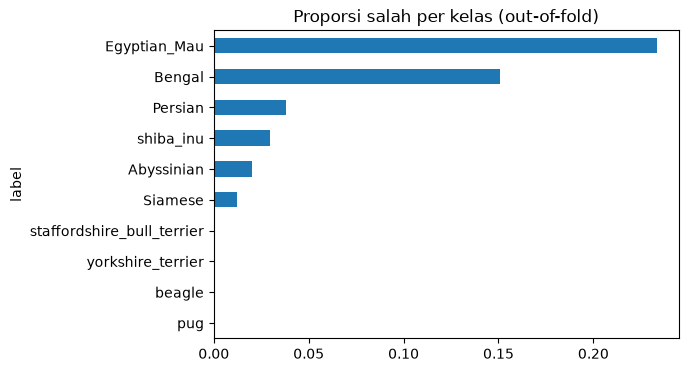

In [12]:
error_by_class = train.groupby(TARGET)["salah"].mean()
error_by_class = error_by_class.sort_values()
error_by_class.plot.barh(title="Proporsi salah per kelas (out-of-fold)", figsize=(6, 4))
plt.savefig(f"{OUTPUT_FOLDER}/salah_per_kelas.png", dpi=120, bbox_inches="tight")
plt.show()
train[[ID_COL, TARGET, "tebakan", "yakin", "salah"]].to_csv(f"{OUTPUT_FOLDER}/oof.csv",
                                                           index=False)

## Cara membaca hasil → tindakan
- **Pasangan kelas tertukar** → lihat gambarnya berdampingan; tambah data/augmentasi yang
  membedakan keduanya, atau backbone lebih kuat (`tta_ensemble`).
- **Yakin tapi salah** → periksa labelnya; bila memang salah label, lihat `label_berisik`.
- **Kelompok gelap/kontras rendah lebih sering salah** → augmentasi kecerahan/kontras.
- **Gambar kecil lebih sering salah** → objek terlalu kecil setelah dikecilkan; naikkan
  `IMAGE_SIZE` atau `ImageOps.pad` agar tidak terpotong.
- **Kelas jarang paling sering salah** → `class_weight`, tambah data kelas itu.